### Etape 1

In [144]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import (
    train_test_split, 
    cross_validate, 
    cross_val_predict,
    StratifiedKFold
    )
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    classification_report, 
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    confusion_matrix
    )
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import pandas as pd
import numpy as np

PARQUET_FILE = '../data/clean/nutriscope_ml_sample.parquet'

dataframe = pd.read_parquet(PARQUET_FILE)

display(dataframe.shape)

display(dataframe.dtypes)

display(dataframe.head())

(30041, 21)

code                                  str
product_name                          str
brands                                str
pnns_groups_1                         str
pnns_groups_2                         str
nova_group                          Int64
additives_n                         Int64
energy-kcal_100g                  float64
fat_100g                          float64
saturated-fat_100g                float64
carbohydrates_100g                float64
sugars_100g                       float64
fiber_100g                        float64
proteins_100g                     float64
salt_100g                         float64
fruits-vegetables-legumes_100g    float64
nutriscore_score                    Int64
nutriscore_grade                      str
completeness                      float64
last_modified                      string
split                                 str
dtype: object

,code,product_name,brands,pnns_groups_1,pnns_groups_2,nova_group,additives_n,energy-kcal_100g,fat_100g,saturated-fat_100g,...,sugars_100g,fiber_100g,proteins_100g,salt_100g,fruits-vegetables-legumes_100g,nutriscore_score,nutriscore_grade,completeness,last_modified,split
0,0000112302660,Soupe potiron et kiri,Liebig,Fruits and vegetables,Soups,4,4,38.300000,1.50000,1.000000,...,2.000000,0.800000,0.90000,0.740000,34.312500,3,c,0.6875,2026-03-14,train
1,0000112302705,velouté de tomates et pointe d'origan,Liebig,Fruits and vegetables,Soups,4,0,28.000000,0.50000,0.300000,...,2.400000,1.000000,0.70000,0.670000,72.977007,1,b,0.7625,2026-03-19,test
2,0000112302754,pur soup' mouliné de 5 légumes verts,liebig,Composite foods,One-dish meals,3,0,24.802376,0.16035,0.044483,...,0.738538,0.837462,0.81314,0.035146,23.242188,0,a,0.9750,2026-03-26,train
3,0000112307261,Velouté de 10 légumes,Liebig,Fruits and vegetables,Soups,4,0,43.000000,1.60000,0.600000,...,1.300000,0.800000,0.70000,0.670000,34.981336,3,c,0.9000,2026-03-26,train
4,0000300000004,Lentilles Brunes Bio,Kazidomi,Composite foods,One-dish meals,3,0,54.000000,0.30000,0.000000,...,0.000000,4.000000,4.00000,0.080000,100.000000,-7,a,0.8875,2026-03-17,test


#### Définitions de fonctions, variables, constantes

In [145]:
SCORING = ["f1_macro", "accuracy", "balanced_accuracy"]
CROSS_VALIDATION = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluate_model(y_true, y_pred, nom: str) -> dict[str, float]:
    """Affiche et retourne les métriques principales d'un modèle de classification."""
    metriques = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
    }

    print(f"=== {nom} ===")
    for cle, valeur in metriques.items():
        print(f"{cle:<12}: {valeur:.4f}")
    print(classification_report(y_true, y_pred, zero_division=0))

    return metriques

def evaluate_cross_validation(pipeline: Pipeline, X, y, nom: str) -> dict[str, float | str]:
    '''Evalue un pipeline en validation croisée (moyenne et écart-type par métrique)'''
    scores = cross_validate(
        pipeline, 
        X, 
        y, 
        cv=CROSS_VALIDATION, 
        scoring=SCORING,
        n_jobs=-1
    )

    resume: dict[str, float | str] = {'modele': nom}

    for metric in SCORING:
        values = scores[f'test_{metric}']
        resume[f'{metric}_moy'] = values.mean()
        resume[f'{metric}_std'] = values.std()

    resume["fit_time_moy"] = scores["fit_time"].mean()
    resume["score_time_moy"] = scores["score_time"].mean()

    return resume    

def build_pipeline(classifier) -> Pipeline:
    return Pipeline(
        steps=[
            ('preprocessor', preprocessor),
            ('classifier', classifier)
        ]
    )

models = {
    'dummy_most_frequent': DummyClassifier(strategy='most_frequent'),
    'dummy_stratified': DummyClassifier(strategy="stratified", random_state=42),
    'tree_depth_3': DecisionTreeClassifier(max_depth=3, random_state=42),
    'tree_depth_8': DecisionTreeClassifier(max_depth=8, random_state=42),
}

#### Preprocessing

In [146]:
features_to_keep = [
    'energy-kcal_100g',
    'fat_100g',
    'saturated-fat_100g',
    'carbohydrates_100g',
    'sugars_100g',
    'proteins_100g',
    'salt_100g',
    'fiber_100g',
    'fruits-vegetables-legumes_100g',
    'nova_group',
    'additives_n',
    'pnns_groups_1',
    'pnns_groups_2'
]

target = 'nutriscore_grade'

X = dataframe[features_to_keep].copy()
y = dataframe[target].copy()

# Identification des types de colonnes
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.to_list()
categorical_features = X.select_dtypes(include=["object", "str"]).columns.to_list()

print(f"Variables numériques : {numeric_features}")
print(f"Variables catégorielles : {categorical_features}")

Variables numériques : ['energy-kcal_100g', 'fat_100g', 'saturated-fat_100g', 'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'salt_100g', 'fiber_100g', 'fruits-vegetables-legumes_100g', 'nova_group', 'additives_n']
Variables catégorielles : ['pnns_groups_1', 'pnns_groups_2']


#### Création des pipelines et des transformers

In [147]:
# Pipeline pour les variables numériques
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")), # Remplace NaN par la médiane
    ("scaler", StandardScaler())
])

# Pipeline pour les variables catégorielles
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")), # remplace NaN par missing
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Appliquer les pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

#### Séparation train + test

In [148]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2, # 20% pour les tests, 80% pour l'entrainement
    random_state=42,
    stratify=y # Maintient les proportions de classes
)

In [149]:
results = [
    evaluate_cross_validation(build_pipeline(classifier), X_train, y_train, name)
    for name, classifier in models.items()
]

comparatif = pd.DataFrame(results).set_index("modele")
comparatif.round(4)

,f1_macro_moy,f1_macro_std,accuracy_moy,accuracy_std,balanced_accuracy_moy,balanced_accuracy_std,fit_time_moy,score_time_moy
modele,,,,,,,,
dummy_most_frequent,0.0891,0.0000,0.2864,0.0001,0.2000,0.0000,0.0939,0.0297
dummy_stratified,0.1987,0.0048,0.2240,0.0052,0.1987,0.0048,0.0836,0.0361
tree_depth_3,0.3979,0.0199,0.5368,0.0101,0.4365,0.0114,0.1509,0.0409
tree_depth_8,0.7449,0.0074,0.7758,0.0045,0.7430,0.0082,0.2683,0.0335


#### Test de prédiction - Arbre de profondeur 3

In [150]:
from sklearn.metrics import confusion_matrix

tree_3 = build_pipeline(models["tree_depth_3"])
tree_3.fit(X_train, y_train)
y_pred_3 = tree_3.predict(X_test)

print(pd.Series(y_pred_3).value_counts())
print(confusion_matrix(y_test, y_pred_3, labels=["a", "b", "c", "d", "e"]))

c    2532
d    1945
e    1420
b     112
Name: count, dtype: int64
[[   0    0  782   12   12]
 [   0   78  518   38   12]
 [   0   24  862  324   37]
 [   0    1  259 1101  228]
 [   0    9  111  470 1131]]


#### Test de prédiction - Arbre de profondeur 8

In [151]:
from sklearn.model_selection import cross_validate

scores = cross_validate(
    build_pipeline(models["tree_depth_8"]),
    X_train, y_train,
    cv=CROSS_VALIDATION,
    scoring="f1_macro",
    return_train_score=True,
    n_jobs=-1,
)

print(f"Train : {scores['train_score'].mean():.4f}")
print(f"Val   : {scores['test_score'].mean():.4f}")

Train : 0.7660
Val   : 0.7449


### Etape 2
#### Features dérivées

In [152]:
DERIVED_NAMES = ["sugars_ratio", "sat_fat_ratio", "energy_gap"]

def add_derived_features(X: pd.DataFrame) -> pd.DataFrame:
    """Ajoute deux ratios et l'écart entre énergie déclarée et énergie recalculée."""
    X = X.astype("float64")  # Int64 nullable -> float, pd.NA -> NaN
    output = X.copy()

    # where(>0) : un dénominateur nul ou absent donne NaN, jamais inf
    output["sugars_ratio"] = X["sugars_100g"] / X["carbohydrates_100g"].where(X["carbohydrates_100g"] > 0)
    output["sat_fat_ratio"] = X["saturated-fat_100g"] / X["fat_100g"].where(X["fat_100g"] > 0)

    # Facteurs d'Atwater : 4 kcal/g (protéines, glucides), 9 (lipides), ~2 (fibres)
    energy_computed = (
        4 * X["proteins_100g"] + 4 * X["carbohydrates_100g"]
        + 9 * X["fat_100g"] + 2 * X["fiber_100g"]
    )
    output["energy_gap"] = X["energy-kcal_100g"] - energy_computed

    return output

def derived_feature_names(transformer, input_features):
    return [*input_features, *DERIVED_NAMES]

#### Préparateur complet

In [153]:
numeric_transformer = Pipeline(steps=[
    ("derive", FunctionTransformer(add_derived_features, feature_names_out=derived_feature_names)),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

models_step2 = {
    "logreg": LogisticRegression(max_iter=1000, random_state=42),
    "random_forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

#### Point de contrôle - Pas de fuite

In [154]:
preprocessor.fit(X_train)
Xt_train = preprocessor.transform(X_train)
Xt_test = preprocessor.transform(X_test)

n_num = len(preprocessor.named_transformers_["num"].get_feature_names_out())
mean_train = Xt_train[:, :n_num].mean(axis=0)
mean_test = Xt_test[:, :n_num].mean(axis=0)

assert np.allclose(mean_train, 0, atol=1e-9), "Le train standardisé devrait être centré"
assert np.abs(mean_test).max() > 1e-3, "Le test ne devrait PAS être centré : fuite ?"
print(f"Max |moyenne| train : {np.abs(mean_train).max():.2e}")
print(f"Max |moyenne| test  : {np.abs(mean_test).max():.2e}")

Max |moyenne| train : 1.74e-15
Max |moyenne| test  : 1.60e-01


#### Point de contrôle sur le nombre de colonnes

In [155]:
names = preprocessor.get_feature_names_out()
print(f"{X_train.shape[1]} colonnes brutes -> {len(names)} colonnes en sortie")
print([n for n in names if n.startswith("cat__")])

13 colonnes brutes -> 60 colonnes en sortie
['cat__pnns_groups_1_Beverages', 'cat__pnns_groups_1_Cereals and potatoes', 'cat__pnns_groups_1_Composite foods', 'cat__pnns_groups_1_Fat and sauces', 'cat__pnns_groups_1_Fish Meat Eggs', 'cat__pnns_groups_1_Fruits and vegetables', 'cat__pnns_groups_1_Milk and dairy products', 'cat__pnns_groups_1_Salty snacks', 'cat__pnns_groups_1_Sugary snacks', 'cat__pnns_groups_1_infrequent_sklearn', 'cat__pnns_groups_2_Appetizers', 'cat__pnns_groups_2_Biscuits and cakes', 'cat__pnns_groups_2_Bread', 'cat__pnns_groups_2_Breakfast cereals', 'cat__pnns_groups_2_Cereals', 'cat__pnns_groups_2_Cheese', 'cat__pnns_groups_2_Chocolate products', 'cat__pnns_groups_2_Dairy desserts', 'cat__pnns_groups_2_Dressings and sauces', 'cat__pnns_groups_2_Dried fruits', 'cat__pnns_groups_2_Fats', 'cat__pnns_groups_2_Fish and seafood', 'cat__pnns_groups_2_Fruit juices', 'cat__pnns_groups_2_Fruits', 'cat__pnns_groups_2_Ice cream', 'cat__pnns_groups_2_Legumes', 'cat__pnns_groups

#### Les deux modèles en Cross Validation

In [156]:
resultats_step2 = [
    evaluate_cross_validation(build_pipeline(clf), X_train, y_train, nom)
    for nom, clf in models_step2.items()
]
pd.DataFrame(resultats_step2).set_index("modele").round(4)

,f1_macro_moy,f1_macro_std,accuracy_moy,accuracy_std,balanced_accuracy_moy,balanced_accuracy_std,fit_time_moy,score_time_moy
modele,,,,,,,,
logreg,0.7605,0.0028,0.8001,0.0015,0.7594,0.0020,1.0555,0.0392
random_forest,0.8530,0.0035,0.8732,0.0041,0.8483,0.0037,3.9442,0.1800


#### Etape 3
##### Point de contrôle 6 - Des plis strictement identiques

In [157]:
splits_1 = list(CROSS_VALIDATION.split(X_train, y_train))
splits_2 = list(CROSS_VALIDATION.split(X_train, y_train))

assert all(
    np.array_equal(train_1, train_2) and np.array_equal(test_1, test_2)
    for (train_1, test_1), (train_2, test_2) in zip(splits_1, splits_2)
), "Les plis diffèrent d'un appel à l'autre"
print("PC6 OK : les plis sont identiques")

PC6 OK : les plis sont identiques


##### Le tableau unique 

In [158]:
tous_les_modeles = {**models, **models_step2}

results_step3 = [
    evaluate_cross_validation(build_pipeline(clf), X_train, y_train, name)
    for name, clf in tous_les_modeles.items()
]

tableau = pd.DataFrame(results_step3).set_index("modele")
tableau.round(4)

,f1_macro_moy,f1_macro_std,accuracy_moy,accuracy_std,balanced_accuracy_moy,balanced_accuracy_std,fit_time_moy,score_time_moy
modele,,,,,,,,
dummy_most_frequent,0.0891,0.0000,0.2864,0.0001,0.2000,0.0000,0.1017,0.0252
dummy_stratified,0.1987,0.0048,0.2240,0.0052,0.1987,0.0048,0.0970,0.0381
tree_depth_3,0.4017,0.0218,0.5370,0.0104,0.4385,0.0124,0.1492,0.0329
tree_depth_8,0.7462,0.0080,0.7770,0.0058,0.7438,0.0087,0.2191,0.0378
logreg,0.7605,0.0028,0.8001,0.0015,0.7594,0.0020,0.8864,0.0336
random_forest,0.8530,0.0035,0.8732,0.0041,0.8483,0.0037,3.8409,0.1759


##### Matrice de confusion normalisée par ligne

PC5 OK : somme par ligne = [1. 1. 1. 1. 1.]


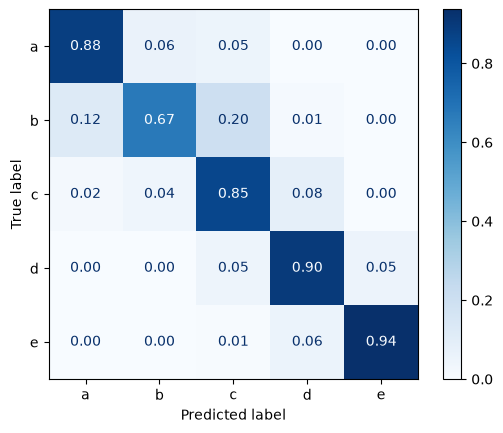

In [159]:
LABELS = ["a", "b", "c", "d", "e"]

meilleur = build_pipeline(models_step2["random_forest"])  # à adapter selon ton tableau
y_pred_cv = cross_val_predict(meilleur, X_train, y_train, cv=CROSS_VALIDATION, n_jobs=-1)

cm = confusion_matrix(y_train, y_pred_cv, labels=LABELS, normalize="true")

assert np.allclose(cm.sum(axis=1), 1), "Chaque ligne doit sommer à 1"
print("PC5 OK : somme par ligne =", cm.sum(axis=1).round(6))

ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(values_format=".2f", cmap="Blues")

#### Mesure du déséquilibre

In [160]:
counts = y_train.value_counts().sort_index()
print(counts)
print(f"Rapport majoritaire / minoritaire : {counts.max() / counts.min():.2f}")

nutriscore_grade
a    3224
b    2584
c    4988
d    6353
e    6883
Name: count, dtype: int64
Rapport majoritaire / minoritaire : 2.66


#### Comparaison - brut vs class_weight vs SMOTE

In [161]:
def build_smote_pipeline(classifier) -> ImbPipeline:
    """SMOTE est appliqué uniquement aux données d'entraînement de chaque pli."""
    return ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", classifier),
    ])


candidats = {
    "rf_brut": build_pipeline(RandomForestClassifier(n_estimators=200, random_state=42)),
    "rf_balanced": build_pipeline(
        RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
    ),
    "rf_smote": build_smote_pipeline(RandomForestClassifier(n_estimators=200, random_state=42)),
}

resultats_desequilibre = [
    evaluate_cross_validation(pipeline, X_train, y_train, nom)
    for nom, pipeline in candidats.items()
]

pd.DataFrame(resultats_desequilibre).set_index("modele").round(4)

,f1_macro_moy,f1_macro_std,accuracy_moy,accuracy_std,balanced_accuracy_moy,balanced_accuracy_std,fit_time_moy,score_time_moy
modele,,,,,,,,
rf_brut,0.853,0.0035,0.8732,0.0041,0.8483,0.0037,3.7870,0.1762
rf_balanced,0.858,0.0039,0.8749,0.0035,0.8580,0.0038,3.9419,0.1791
rf_smote,0.857,0.0036,0.8747,0.0033,0.8567,0.0036,6.3125,0.1777


In [162]:
def f1_par_pli(pipeline):
    return cross_validate(pipeline, X_train, y_train, cv=CROSS_VALIDATION,
                          scoring="f1_macro", n_jobs=-1)["test_score"]

f1_brut = f1_par_pli(candidats["rf_brut"])
f1_bal = f1_par_pli(candidats["rf_balanced"])

diff = f1_bal - f1_brut
print(diff.round(4))
print(f"Gain moyen : {diff.mean():.4f} | écart-type des gains : {diff.std():.4f}")

[0.0039 0.0014 0.0093 0.0038 0.0066]
Gain moyen : 0.0050 | écart-type des gains : 0.0027


#### Etape 4

In [163]:
def build_preprocessor(numeric_cols: list[str], categorical_cols: list[str]) -> ColumnTransformer:
    numeric = Pipeline(steps=[
        ("derive", FunctionTransformer(add_derived_features, feature_names_out=derived_feature_names)),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)),
    ])
    return ColumnTransformer(transformers=[
        ("num", numeric, numeric_cols),
        ("cat", categorical, categorical_cols),
    ])


def make_pipeline(numeric_cols: list[str], categorical_cols: list[str]) -> Pipeline:
    return Pipeline(steps=[
        ("preprocessor", build_preprocessor(numeric_cols, categorical_cols)),
        ("classifier", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)),
    ])

In [164]:
def run_experiment(extra_columns: list[str], nom: str) -> tuple[dict, pd.DataFrame]:
    """CV + importance par permutation, avec éventuellement des colonnes en plus."""
    cols = features_to_keep + extra_columns
    X_exp = dataframe.loc[X_train.index, cols]  # mêmes lignes que X_train
    pipe = make_pipeline(numeric_features + extra_columns, categorical_features)

    resume_cv = evaluate_cross_validation(pipe, X_exp, y_train, nom)

    # Pli de validation interne au train : le modèle ne le voit pas à l'ajustement
    X_fit, X_val, y_fit, y_val = train_test_split(
        X_exp, y_train, test_size=0.25, stratify=y_train, random_state=42
    )
    pipe.fit(X_fit, y_fit)
    perm = permutation_importance(
        pipe, X_val, y_val, scoring="f1_macro", n_repeats=5, random_state=42, n_jobs=-1
    )

    importances = pd.DataFrame(
        {"mean": perm.importances_mean, "std": perm.importances_std}, index=X_val.columns
    ).sort_values("mean", ascending=False)
    positives = importances["mean"].clip(lower=0)
    importances["part"] = positives / positives.sum()
    return resume_cv, importances

In [165]:
cv_fuite, imp_fuite = run_experiment(["nutriscore_score"], "avec_fuite")
print(f"F1 macro avec fuite : {cv_fuite['f1_macro_moy']:.4f} ± {cv_fuite['f1_macro_std']:.4f}")
print(imp_fuite.head(5).round(4))

assert cv_fuite["f1_macro_moy"] > 0.97, "Avec la fuite, on attend plus de 0,97"

F1 macro avec fuite : 0.9861 ± 0.0026
                    mean     std    part
nutriscore_score  0.6721  0.0032  0.9091
pnns_groups_1     0.0165  0.0013  0.0223
proteins_100g     0.0147  0.0017  0.0199
sugars_100g       0.0079  0.0005  0.0107
salt_100g         0.0059  0.0004  0.0080


In [166]:
FORBIDDEN_FEATURES = {"nutriscore_score", "nutriscore_grade"}


def assert_no_target_leak(input_columns) -> None:
    leaked = FORBIDDEN_FEATURES & set(input_columns)
    assert not leaked, f"Fuite de la cible : {sorted(leaked)} ne doit pas être une feature"


def test_no_target_leak() -> None:
    # 1. La liste de features
    assert_no_target_leak(features_to_keep)
    # 2. Les colonnes d'entrée réelles
    assert_no_target_leak(X_train.columns)
    # 3. Les colonnes produites par le préparateur
    prep = clone(preprocessor).fit(X_train)
    assert not any("nutriscore" in nom for nom in prep.get_feature_names_out())


test_no_target_leak()
print("Test anti-fuite OK")

# On vérifie que le test détecte bien la fuite
try:
    assert_no_target_leak(features_to_keep + ["nutriscore_score"])
except AssertionError as e:
    print("Le test détecte bien la fuite :", e)

Test anti-fuite OK
Le test détecte bien la fuite : Fuite de la cible : ['nutriscore_score'] ne doit pas être une feature


In [167]:
cv_ctrl, imp_ctrl = run_experiment(["completeness"], "controle_completeness")
print(f"F1 macro avec completeness : {cv_ctrl['f1_macro_moy']:.4f} ± {cv_ctrl['f1_macro_std']:.4f}")

ligne = imp_ctrl.loc["completeness"]
print(ligne.round(4))
print("Signalée ?", ligne["mean"] > 2 * ligne["std"])

F1 macro avec completeness : 0.8566 ± 0.0055
mean   -0.0018
std     0.0013
part    0.0000
Name: completeness, dtype: float64
Signalée ? False


In [168]:
cv_honnete, imp_honnete = run_experiment([], "honnete")
print(f"F1 macro honnête : {cv_honnete['f1_macro_moy']:.4f}")
assert cv_honnete["f1_macro_moy"] < 0.90, "Sans la colonne, on attend moins de 0,90 : autre fuite ?"

BAREME = {
    "energy-kcal_100g": "défavorable",
    "sugars_100g": "défavorable",
    "saturated-fat_100g": "défavorable",
    "salt_100g": "défavorable",
    "fiber_100g": "favorable",
    "proteins_100g": "favorable",
    "fruits-vegetables-legumes_100g": "favorable",
}

imp_honnete["composante"] = imp_honnete.index.map(lambda c: BAREME.get(c, "hors barème"))
print(imp_honnete.round(4))
print(imp_honnete.groupby("composante")["part"].sum().round(3))

# Proxy ? Corrélation des colonnes hors barème avec les composantes
print(X_train[["carbohydrates_100g", "sugars_100g", "fat_100g", "saturated-fat_100g"]]
      .astype("float64").corr().round(2))

F1 macro honnête : 0.8580
                                  mean     std    part   composante
saturated-fat_100g              0.1953  0.0071  0.2444  défavorable
salt_100g                       0.1946  0.0040  0.2434  défavorable
sugars_100g                     0.1591  0.0041  0.1990  défavorable
proteins_100g                   0.0714  0.0040  0.0894    favorable
fat_100g                        0.0475  0.0021  0.0595  hors barème
energy-kcal_100g                0.0265  0.0014  0.0331  défavorable
carbohydrates_100g              0.0254  0.0021  0.0318  hors barème
fruits-vegetables-legumes_100g  0.0240  0.0017  0.0300    favorable
pnns_groups_1                   0.0220  0.0024  0.0275  hors barème
fiber_100g                      0.0219  0.0019  0.0274    favorable
nova_group                      0.0049  0.0009  0.0061  hors barème
pnns_groups_2                   0.0043  0.0012  0.0054  hors barème
additives_n                     0.0024  0.0015  0.0029  hors barème
composante
défavorable

#### Etape 5
##### Test final

In [169]:
modele_final = make_pipeline(numeric_features, categorical_features)  # RF, class_weight="balanced"
modele_final.fit(X_train, y_train)

y_pred_test = modele_final.predict(X_test)
metriques_test = evaluate_model(y_test, y_pred_test, "RF balanced (test final)")

ecart = abs(cv_honnete["f1_macro_moy"] - metriques_test["f1_macro"])
print(f"Écart CV / test : {ecart:.4f}")
assert ecart <= 0.05, "PC11 non respecté : split non représentatif ?"

=== RF balanced (test final) ===
accuracy    : 0.8822
f1_macro    : 0.8658
f1_weighted : 0.8826
balanced_accuracy: 0.8658
              precision    recall  f1-score   support

           a       0.89      0.87      0.88       806
           b       0.77      0.76      0.76       646
           c       0.83      0.87      0.85      1247
           d       0.89      0.90      0.89      1589
           e       0.96      0.93      0.94      1721

    accuracy                           0.88      6009
   macro avg       0.87      0.87      0.87      6009
weighted avg       0.88      0.88      0.88      6009

Écart CV / test : 0.0078


##### Les erreurs triées

In [170]:
ORDRE = {g: i for i, g in enumerate(LABELS)}

proba = modele_final.predict_proba(X_test)
classes = list(modele_final.classes_)

erreurs = dataframe.loc[X_test.index, ["code", "product_name", *features_to_keep]].copy()
erreurs["grade_vrai"] = y_test
erreurs["grade_predit"] = y_pred_test
erreurs["ecart_grade"] = (
    erreurs["grade_vrai"].map(ORDRE) - erreurs["grade_predit"].map(ORDRE)
).abs()
erreurs["confiance"] = proba.max(axis=1)

erreurs = (
    erreurs[erreurs["grade_vrai"] != erreurs["grade_predit"]]
    .sort_values(["ecart_grade", "confiance"], ascending=False)
)

print(f"{len(erreurs)} erreurs sur {len(y_test)} produits")
print(erreurs["ecart_grade"].value_counts().sort_index())

colonnes_vue = ["code", "product_name", "grade_vrai", "grade_predit",
                "ecart_grade", "confiance", *numeric_features[:9]]
erreurs[colonnes_vue].head(15).round(2)

708 erreurs sur 6009 produits
ecart_grade
1    626
2     71
3      6
4      5
Name: count, dtype: int64


,code,product_name,grade_vrai,grade_predit,ecart_grade,confiance,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits-vegetables-legumes_100g
9864,3257987651665,Cœur fondant au chocolat noir,a,e,4,0.99,430.53,25.26,14.74,42.11,33.68,6.74,0.13,NaN,NaN
12151,3292590853020,2 boudins blancs au foie de canard,a,e,4,0.94,310.91,29.09,10.91,2.18,1.18,9.09,1.73,0.55,NaN
11868,3285320699524,Émincé de dinde,e,a,4,0.34,107.00,1.30,0.40,0.00,0.00,23.70,23.70,0.00,NaN
3196,2106662007055,Filet mignon de porc,e,a,4,0.32,119.00,3.00,1.00,0.00,0.00,23.00,45.72,0.00,0.0
1412,0240609066919,Haddock,e,a,4,0.26,101.00,0.70,0.10,0.00,0.00,24.00,4.60,NaN,NaN
22311,4016369521045,Élixir du suedois,e,b,3,0.54,107.00,0.10,0.00,2.50,0.00,0.10,0.00,NaN,25.6
27340,8012666007011,Crunchy 5 fruits secs,a,d,3,0.52,206.00,8.00,4.80,29.00,9.90,3.40,0.21,2.60,NaN
4978,2699199081211,Filet de crocodile,d,a,3,0.50,151.00,73.00,1.50,1.90,0.30,20.00,0.71,NaN,NaN
21153,3760285890051,Fruit Ride Framboise pomme,a,d,3,0.47,402.00,0.00,0.00,94.00,62.00,0.00,0.00,13.00,NaN
19609,3760030721227,Lait D'amande Omega En Poudre Bio - 800 G - La...,d,a,3,0.40,395.00,6.90,0.80,59.00,14.00,20.00,0.08,9.40,0.0


##### Récupération de 3 cas

In [171]:
tres_confiantes = erreurs[(erreurs["ecart_grade"] >= 2) & (erreurs["confiance"] >= 0.7)]
print(f"{len(tres_confiantes)} erreurs très confiantes d'au moins 2 crans")
print(tres_confiantes["pnns_groups_1"].value_counts())

tres_confiantes[colonnes_vue].head(20).round(2)

14 erreurs très confiantes d'au moins 2 crans
pnns_groups_1
Milk and dairy products    4
Fish Meat Eggs             3
Fruits and vegetables      3
Salty snacks               2
Sugary snacks              1
Composite foods            1
Name: count, dtype: int64


,code,product_name,grade_vrai,grade_predit,ecart_grade,confiance,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,proteins_100g,salt_100g,fiber_100g,fruits-vegetables-legumes_100g
9864,3257987651665,Cœur fondant au chocolat noir,a,e,4,0.99,430.53,25.26,14.74,42.11,33.68,6.74,0.13,NaN,NaN
12151,3292590853020,2 boudins blancs au foie de canard,a,e,4,0.94,310.91,29.09,10.91,2.18,1.18,9.09,1.73,0.55,NaN
21828,3770023324311,Yaourt à boire aromatisé vanille,e,c,2,0.98,89.00,4.00,2.70,12.20,12.20,3.30,0.15,NaN,NaN
28615,8433329088688,Anacardos fritos y salados,d,b,2,0.92,624.00,50.00,8.50,24.00,6.00,18.00,0.09,NaN,NaN
13792,3374270040224,Yaourts cerise,e,c,2,0.90,95.00,2.50,1.60,14.90,14.30,3.30,0.01,NaN,60.00
11995,3291330006849,Lait chocolaté,e,c,2,0.88,126.00,3.50,2.10,17.10,16.20,6.10,0.10,NaN,NaN
2521,20047238,Nussmix,c,a,2,0.82,646.67,58.00,6.33,6.40,4.33,20.30,0.03,8.67,0.00
15818,3512690003775,Fusili Dinde & Emmental,a,c,2,0.82,174.00,7.70,3.92,18.70,0.60,6.50,0.93,NaN,NaN
18402,3661945410063,Melange de fruits exotiques,a,c,2,0.80,74.00,0.10,0.00,17.30,17.10,0.30,0.01,NaN,NaN
16938,3564700693124,Yaourt à boire chocolat,e,c,2,0.77,88.70,1.90,1.20,13.70,12.00,4.00,0.10,0.40,0.00
